[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jhconning/hunter_eco701/blob/main/notebooks/topic02_fsolve_intro.ipynb)

# Topic 2: Solving Equations Numerically with `fsolve`

**ECO 701: Microeconomic Theory** | Hunter College, CUNY
*Instructor: Jonathan Conning*

---

A great deal of economic analysis ends in the same place: **a set of equations to solve.** First-order conditions set marginal benefit equal to marginal cost. Best-response functions have to hold for every player at once in a Nash equilibrium. Supply has to equal demand. When the equations are simple you solve them by hand, and you should. When they are messy, or when you want to check your algebra, a computer can find the solution numerically.

`scipy.optimize.fsolve` is a **root finder**: you give it a function $f$ and a starting guess, and it searches for a point where $f = 0$. Using it takes three steps:

1. **Rewrite every equation so one side is zero.** For example, $y = x^2$ becomes $y - x^2 = 0$.
2. **Write a Python function that returns the left-hand sides.** These are called *residuals*; at a solution, every residual is zero.
3. **Call `fsolve` with that function and an initial guess.**

The first two examples below follow the introductory `fsolve` problems in [APMonitor's Python tutorials](https://apmonitor.com/che263/index.php/Main/PythonSolveEquations) by John Hedengren (BYU), also covered in his video [*Python Nonlinear Equations with Scipy fsolve*](https://www.youtube.com/watch?v=v4R6K4RxADE). The third applies the same steps to a Nash equilibrium from lecture.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

## Example 1: One Equation, One Unknown

Solve

$$y^2 + y - 4 = 0.$$

This one we can check by hand. The quadratic formula gives $y = \dfrac{-1 \pm \sqrt{17}}{2}$, so there are **two** solutions: $y \approx 1.562$ and $y \approx -2.562$.

The equation already has zero on the right, so the residual function just returns the left-hand side.

In [2]:
def f(y):
    return y**2 + y - 4

print(fsolve(f, 1))     # start the search at y = 1
print(fsolve(f, -2))    # start the search at y = -2

[1.56155281]
[-2.56155281]


Two different starting guesses produce the two different roots. **`fsolve` finds one solution, usually the one nearest where it starts.** It cannot tell you how many solutions exist, so a plot is often the fastest way to see what you are looking for.

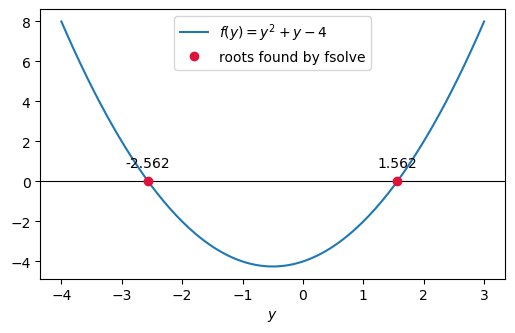

In [3]:
y = np.linspace(-4, 3, 200)
roots = [fsolve(f, 1)[0], fsolve(f, -2)[0]]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(y, f(y), label=r"$f(y) = y^2 + y - 4$")
ax.axhline(0, color="black", lw=0.8)
ax.plot(roots, [0, 0], "o", color="crimson", label="roots found by fsolve")
for r in roots:
    ax.annotate(f"{r:.3f}", (r, 0), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_xlabel("$y$")
ax.legend()
plt.show()

## Example 2: Two Equations, Two Unknowns

Now $x$ and $y$ depend on each other:

$$x = y, \qquad y = x^2 + 2x - 4.$$

Step 1, move everything to one side:

$$x - y = 0, \qquad y - x^2 - 2x + 4 = 0.$$

Step 2, the function takes **both** unknowns packed into one array and returns **both** residuals as a list. Step 3, the initial guess now needs two numbers.

In [4]:
def f2(z):
    x, y = z
    return [x - y,
            y - x**2 - 2*x + 4]

print(fsolve(f2, [1, 1]))
print(fsolve(f2, [-2, -2]))

[1.56155281 1.56155281]
[-2.56155281 -2.56155281]


Again there are two solutions, and again the starting point decides which one `fsolve` returns. Geometrically, each solution is a point where the two curves cross.

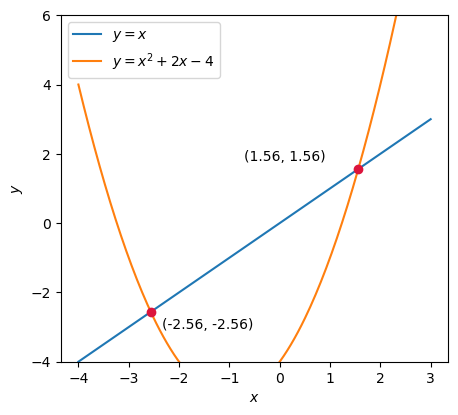

In [5]:
x = np.linspace(-4, 3, 200)
sols = [fsolve(f2, [1, 1]), fsolve(f2, [-2, -2])]

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(x, x, label="$y = x$")
ax.plot(x, x**2 + 2*x - 4, label="$y = x^2 + 2x - 4$")
for s in sols:
    ax.plot(*s, "o", color="crimson")
    offset = (-82, 6) if s[0] > 0 else (8, -12)    # keep labels inside the axes
    ax.annotate(f"({s[0]:.2f}, {s[1]:.2f})", s, textcoords="offset points", xytext=offset)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_ylim(-4, 6)
ax.legend()
plt.show()

## Example 3: A Nash Equilibrium as a System of First-Order Conditions

Back to Alfredo and Bob, who fish the same lake (Topic 1 slides). Each chooses hours of effort; each hour the other fishes lowers my catch per hour. Alfredo's payoff is

$$u_A(e_A, e_B) = \left(15 - \tfrac14 e_B\right) e_A - \tfrac12 e_A^2,$$

and Bob's is the mirror image. Each fisher's best response comes from their first-order condition, taking the other's effort as given:

$$\frac{\partial u_A}{\partial e_A} = 15 - \tfrac14 e_B - e_A = 0, \qquad \frac{\partial u_B}{\partial e_B} = 15 - \tfrac14 e_A - e_B = 0.$$

A **Nash equilibrium** is a pair $(e_A, e_B)$ at which *both* conditions hold at once: two equations, two unknowns. That is exactly the kind of system `fsolve` is built for. (Solving by hand gives $e_A = e_B = 12$, the "12 hours" in the lecture's payoff matrix.)

In [6]:
def focs(e):
    eA, eB = e
    return [15 - 0.25*eB - eA,     # Alfredo's FOC
            15 - 0.25*eA - eB]     # Bob's FOC

eA, eB = fsolve(focs, [10, 10])
uA = (15 - 0.25*eB)*eA - 0.5*eA**2
print(f"Nash equilibrium: e_A = {eA:.2f}, e_B = {eB:.2f};  payoff to each = {uA:.2f}")

Nash equilibrium: e_A = 12.00, e_B = 12.00;  payoff to each = 72.00


**What `fsolve` does *not* do here.** It found a point where both first-order conditions hold. It did not check that each fisher is at a *maximum* rather than a minimum: that is the second-order condition, $\partial^2 u_A / \partial e_A^2 = -1 < 0$, and it is still your job. A root finder solves equations; it knows nothing about the economics that produced them.

To see how the equilibrium responds to the model's parameters, change a number and re-run. For instance, try making fishing more productive by raising 15 to 18 in both conditions.

## Good Habits: Check That It Actually Worked

`fsolve` always returns *something*, even when it fails. Ask for `full_output=True` and it also reports whether it converged (`ier == 1` means success) and a message. Plugging the answer back into your function should give residuals of essentially zero.

Here is a case with no real solution at all, $y^2 + 4 = 0$:

In [7]:
def g(y):
    return y**2 + 4          # never equals zero for real y

sol, info, ier, msg = fsolve(g, 1, full_output=True)
print("returned:", sol)
print("converged?", ier == 1)
print("message:", msg)
print("residual at the 'answer':", g(sol))

returned: [0.00024414]
converged? False
message: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
residual at the 'answer': [4.00000006]


It hands back a number anyway. Only the convergence flag and the non-zero residual tell you not to trust it.

**A short checklist**

* Plug the answer back in: every residual should be close to zero.
* Use `full_output=True` and check `ier == 1`.
* Try more than one initial guess; there may be more than one solution.
* A plot is the quickest way to see how many solutions to expect and where.
* `fsolve` solves equations. To **maximize or minimize** a function directly, possibly under constraints, use `scipy.optimize.minimize` instead: see the [*Topic 2: Optimization Solvers*](topic02_constrained_optimization_numerical.ipynb) notebook.